In [6]:
import numpy as np
import matplotlib.pyplot as plt

GM = 4 * np.pi**2                    # AU^3 / yr^2 (AU, years, solar masses)
x0, y0, vx0, vy0 = 1.0, 0.0, 0.0, 2 * np.pi
dt = 0.001


def derivatives(state):
    x, y, vx, vy = state
    r = np.sqrt(x**2 + y**2)
    ax = -GM * x / r**3
    ay = -GM * y / r**3
    return np.array([vx, vy, ax, ay])


def euler_step(state, dt):
    k1 = derivatives(state)
    return state + dt * k1


def rk4_step(state, dt):
    k1 = derivatives(state)
    k2 = derivatives(state + dt*k1/2)
    k3 = derivatives(state + dt*k2/2)
    k4 = derivatives(state + dt*k3)
    return state + (dt/6)*(k1 + 2*k2 + 2*k3 + k4)


def simulate(method, dt, t_final=1.0):
    state = np.array([x0, y0, vx0, vy0])
    n = int(round(t_final/dt))
    times = np.linspace(0, t_final, n+1)
    states = np.zeros((n+1, 4))
    states[0] = state
    for i in range(n):
        state = method(state, dt)
        states[i+1] = state
    return times, states


def calculate_energy(states):
    x, y, vx, vy = states[:, 0], states[:, 1], states[:, 2], states[:, 3]
    r = np.sqrt(x**2 + y**2)
    return 0.5*(vx**2 + vy**2) - GM/r          # specific mechanical energy


def calculate_angular_momentum(states):
    x, y, vx, vy = states[:, 0], states[:, 1], states[:, 2], states[:, 3]
    return x*vy - y*vx

1 : return to start and the period

In [6]:
def measure_period(method, dt, t_max=2.0):
    """Step until y goes from negative to positive with x > 0 (back at the
    start), then find the exact crossing time with Newton's method."""
    state = np.array([x0, y0, vx0, vy0])
    t = 0.0
    while t < t_max:
        new_state = method(state, dt)
        if state[1] < 0 and new_state[1] >= 0 and new_state[0] > 0:
            tau = dt * (-state[1]) / (new_state[1] - state[1])   # first guess
            for _ in range(5):                                   # improve it
                trial = method(state, tau)
                tau = tau - trial[1] / trial[3]                  # y / vy
            return t + tau
        state = new_state
        t = t + dt
    return np.nan


print("=" * 70)
print("(A) RETURN TO START AFTER 1 YEAR  (dt = 0.001 yr)")
print("=" * 70)
initial_position = np.array([x0, y0])
for name, method in (("Euler", euler_step), ("RK4", rk4_step)):
    period = measure_period(method, dt)
    _, states = simulate(method, dt, 1.0)
    distance = np.linalg.norm(states[-1, :2] - initial_position)
    print(f"{name:5s}: period = {period:.6f} yr  (to 4 digits: {period:.4f}); "
          f"distance from start at t = 1 yr = {distance:.3e} AU")



2:energy and angular momentum drift


(B) DRIFT OVER 10 ORBITS  (dt = 0.001 yr, tolerance = 1e-08)
Euler: max |dE/E0| = 3.33e-01, max |dL/L0| = 2.24e-01  -> EXCEEDS the tolerance
RK4  : max |dE/E0| = 1.71e-11, max |dL/L0| = 8.55e-12  -> within the tolerance


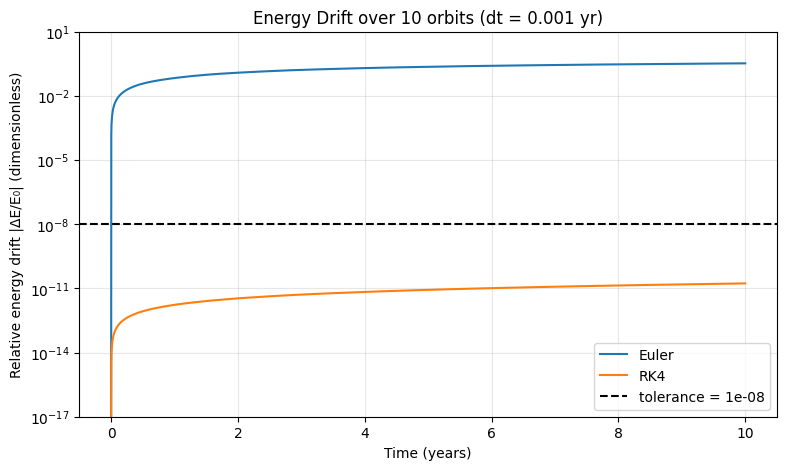

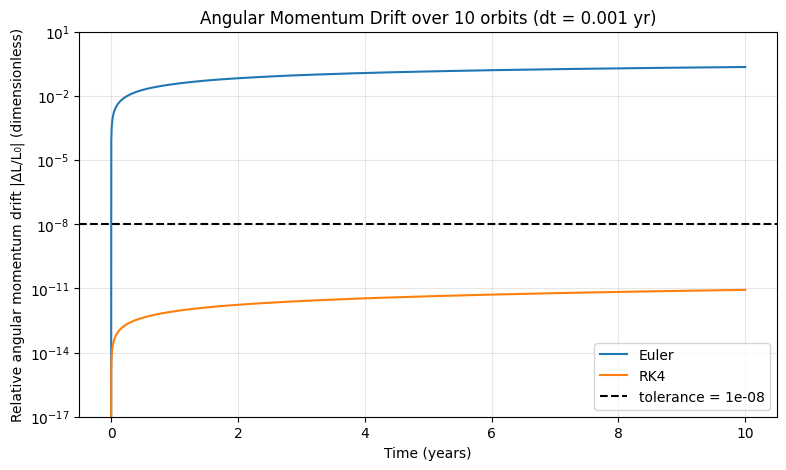

In [ ]:
n_orbits = 10
tolerance = 1e-8              # stated tolerance on the RELATIVE drift

print("\n" + "=" * 70)
print(f"(B) DRIFT OVER {n_orbits} ORBITS  (dt = {dt} yr, tolerance = {tolerance:g})")
print("=" * 70)

t_euler, sol_euler_long = simulate(euler_step, dt, n_orbits)
t_rk4, sol_rk4_long = simulate(rk4_step, dt, n_orbits)

E_euler = calculate_energy(sol_euler_long)
E_rk4 = calculate_energy(sol_rk4_long)
L_euler = calculate_angular_momentum(sol_euler_long)
L_rk4 = calculate_angular_momentum(sol_rk4_long)

E_drift_euler = (E_euler - E_euler[0]) / abs(E_euler[0])
E_drift_rk4 = (E_rk4 - E_rk4[0]) / abs(E_rk4[0])
L_drift_euler = (L_euler - L_euler[0]) / abs(L_euler[0])
L_drift_rk4 = (L_rk4 - L_rk4[0]) / abs(L_rk4[0])

for name, dE, dL in (("Euler", E_drift_euler, L_drift_euler),
                     ("RK4", E_drift_rk4, L_drift_rk4)):
    max_dE = np.max(np.abs(dE))
    max_dL = np.max(np.abs(dL))
    verdict = "within" if max(max_dE, max_dL) < tolerance else "EXCEEDS"
    print(f"{name:5s}: max |dE/E0| = {max_dE:.2e}, max |dL/L0| = {max_dL:.2e}"
          f"  -> {verdict} the tolerance")

floor = 1e-17      # stops log(0) at t = 0
plt.figure(figsize=(9, 5))
plt.semilogy(t_euler, np.maximum(np.abs(E_drift_euler), floor), label="Euler")
plt.semilogy(t_rk4, np.maximum(np.abs(E_drift_rk4), floor), label="RK4")
plt.axhline(tolerance, color="black", linestyle="--",
            label=f"tolerance = {tolerance:g}")
plt.xlabel("Time (years)")
plt.ylabel("Relative energy drift |ΔE/E₀| (dimensionless)")
plt.title(f"Energy Drift over {n_orbits} orbits (dt = {dt} yr)")
plt.ylim(1e-17, 10)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.savefig("energy_drift.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 5))
plt.semilogy(t_euler, np.maximum(np.abs(L_drift_euler), floor), label="Euler")
plt.semilogy(t_rk4, np.maximum(np.abs(L_drift_rk4), floor), label="RK4")
plt.axhline(tolerance, color="black", linestyle="--",
            label=f"tolerance = {tolerance:g}")
plt.xlabel("Time (years)")
plt.ylabel("Relative angular momentum drift |ΔL/L₀| (dimensionless)")
plt.title(f"Angular Momentum Drift over {n_orbits} orbits (dt = {dt} yr)")
plt.ylim(1e-17, 10)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.savefig("angular_momentum_drift.png", dpi=150)
plt.show()

3: convergence study


(C) CONVERGENCE: position error after exactly 1 orbit, dt = 1/N
Euler    dt (yr)      error (AU)    local order
       1.000e-02     2.256e+00    0.66
       5.000e-03     1.429e+00    0.80
       2.500e-03     8.206e-01    0.89
       1.250e-03     4.416e-01    0.95
       6.250e-04     2.291e-01    0.97
       3.125e-04     1.167e-01    0.99
       1.563e-04     5.889e-02    0.99
       7.813e-05     2.958e-02    1.00
       3.906e-05     1.482e-02    1.00
       1.953e-05     7.420e-03       -
RK4      dt (yr)      error (AU)    local order
       1.000e-01     1.074e-01    4.78
       5.000e-02     3.905e-03    4.56
       2.500e-02     1.659e-04    4.39
       1.250e-02     7.931e-06    4.24
       6.250e-03     4.192e-07    4.14
       3.125e-03     2.380e-08    4.07
       1.563e-03     1.413e-09    4.04
       7.813e-04     8.596e-11       -

Measured Euler order: 0.99   (theory: 1)
Measured RK4 order:   4.12   (theory: 4)


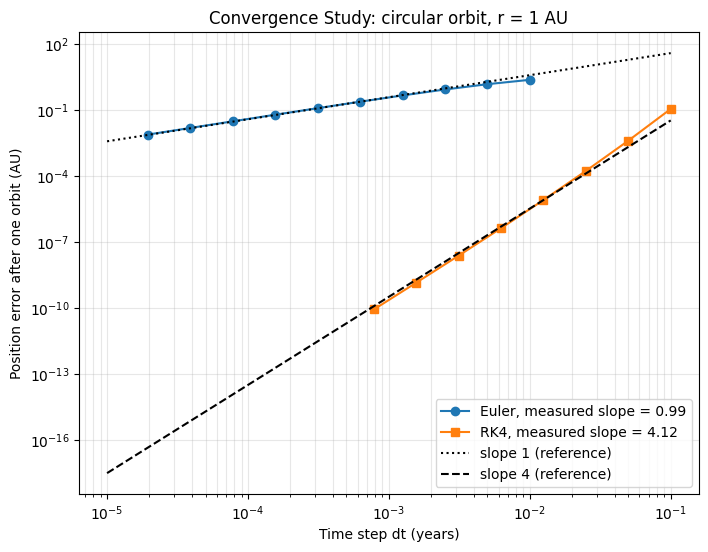

In [ ]:
print("\n" + "=" * 70)
print("(C) CONVERGENCE: position error after exactly 1 orbit, dt = 1/N")
print("=" * 70)


def position_error(method, h):
    _, states = simulate(method, h, 1.0)
    return np.linalg.norm(states[-1, :2] - initial_position)


N_euler = 100 * 2 ** np.arange(10)       # 100, 200, ..., 51200
N_rk4 = 10 * 2 ** np.arange(8)           # 10, 20, ..., 1280
h_euler = 1.0 / N_euler
h_rk4 = 1.0 / N_rk4
errors_euler = np.array([position_error(euler_step, h) for h in h_euler])
errors_rk4 = np.array([position_error(rk4_step, h) for h in h_rk4])

local_euler = np.log2(errors_euler[:-1] / errors_euler[1:])
local_rk4 = np.log2(errors_rk4[:-1] / errors_rk4[1:])

print("Euler    dt (yr)      error (AU)    local order")
for i, (h, e) in enumerate(zip(h_euler, errors_euler)):
    p = f"{local_euler[i]:.2f}" if i < len(local_euler) else "   -"
    print(f"      {h:10.3e}   {e:11.3e}    {p}")
print("RK4      dt (yr)      error (AU)    local order")
for i, (h, e) in enumerate(zip(h_rk4, errors_rk4)):
    p = f"{local_rk4[i]:.2f}" if i < len(local_rk4) else "   -"
    print(f"      {h:10.3e}   {e:11.3e}    {p}")

# Fit only where the straight-line behaviour holds:
#   Euler: dt <= 1e-3;  RK4: errors between 1e-12 (above round-off) and 1e-4
use_euler = h_euler <= 1e-3
use_rk4 = (errors_rk4 > 1e-12) & (errors_rk4 < 1e-4)
order_euler = np.polyfit(np.log(h_euler[use_euler]),
                         np.log(errors_euler[use_euler]), 1)[0]
order_rk4 = np.polyfit(np.log(h_rk4[use_rk4]),
                       np.log(errors_rk4[use_rk4]), 1)[0]

print(f"\nMeasured Euler order: {order_euler:.2f}   (theory: 1)")
print(f"Measured RK4 order:   {order_rk4:.2f}   (theory: 4)")

plt.figure(figsize=(8, 6))
plt.loglog(h_euler, errors_euler, 'o-',
           label=f"Euler, measured slope = {order_euler:.2f}")
plt.loglog(h_rk4, errors_rk4, 's-',
           label=f"RK4, measured slope = {order_rk4:.2f}")
h_line = np.array([1e-5, 1e-1])
plt.loglog(h_line, errors_euler[use_euler][0] * (h_line / h_euler[use_euler][0]),
           'k:', label="slope 1 (reference)")
plt.loglog(h_line, errors_rk4[use_rk4][0] * (h_line / h_rk4[use_rk4][0]) ** 4,
           'k--', label="slope 4 (reference)")
plt.xlabel("Time step dt (years)")
plt.ylabel("Position error after one orbit (AU)")
plt.title("Convergence Study: circular orbit, r = 1 AU")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.savefig("convergence.png", dpi=150)
plt.show()
